# O voto acompanha a renda do município? Quanto, e com que controles

**Pergunta.** No 2º turno de 2026, Lula teve 73,9% dos votos válidos no quarto de municípios com menor
PIB per capita e 44,1% no quarto com maior. A comparação entre quartis mostra uma tendência, mas não diz
**quão forte** é a relação nem se ela se mantém quando se levam em conta a **região** e a
**alfabetização**, que andam junto com a renda.

**O que este notebook faz**

1. Mede a força da relação com a correlação de Spearman (baseada em ordem, robusta a valores extremos),
   sem peso e com peso pelos votos válidos.
2. Estima regressões lineares ponderadas pelos votos válidos: % de Lula ~ log₂(PIB per capita),
   depois + alfabetização, depois + região. Reporta dois intervalos de confiança: robusto (HC1), que
   trata cada município como independente, e **agrupado por UF**, que admite que municípios do mesmo
   estado votam parecido (dependência espacial) e é o mais honesto aqui.
3. Repete a relação dentro de cada região e no 2º turno de 2022, para ver se o resultado é estável.

**Unidade de análise:** município (5.570 com indicadores do IBGE; o exterior fica de fora).
**Os resultados descrevem municípios, não eleitores**, e associação não é causalidade.

**Dados:** `data/limpo/` (gerado por `limpeza_dados.ipynb`), que mantém a alfabetização com decimais.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LIMPO = RAIZ / "data" / "limpo"
FIGURAS = RAIZ / "notebooks" / "figuras"
FIGURAS.mkdir(exist_ok=True)

mun = pd.read_csv(LIMPO / "dMunicipio.csv", sep=";")
votos = pd.read_csv(LIMPO / "fVotos.csv", sep=";")
comp = pd.read_csv(LIMPO / "fComparecimento.csv", sep=";")
REGIOES = {"N": "Norte", "NE": "Nordeste", "SE": "Sudeste", "S": "Sul", "CO": "Centro-Oeste"}
print(f"{len(mun):,} locais · {len(votos):,} linhas de votos · {len(comp):,} linhas de comparecimento".replace(",", "."))

5.766 locais · 309.308 linhas de votos · 45.834 linhas de comparecimento


## 1. Base: um município por linha

`y` é a parcela de Lula nos votos válidos do município; `validos` é o peso (municípios com mais votos
pesam mais, como no resultado nacional); `lpib` é o log₂ do PIB per capita, de modo que o coeficiente
lê-se como **efeito de dobrar o PIB per capita**.

In [2]:
def base(turno: str, candidato: str) -> pd.DataFrame:
    v = votos[(votos.chave_turno == turno) & (votos.chave_candidato == candidato)]
    v = v.groupby("cd_municipio_tse").qt_votos_nominais.sum().rename("votos")
    c = comp[comp.chave_turno == turno].set_index("cd_municipio_tse").votos_validos.rename("validos")
    d = mun[~mun.exterior].set_index("cd_municipio_tse").join(v).join(c)
    d = d.dropna(subset=["pib_per_capita", "alfabetizacao_2022", "votos", "validos"])
    d = d[d.validos > 0].copy()
    d["y"] = d.votos / d.validos
    d["lpib"] = np.log2(d.pib_per_capita)
    d["regiao"] = d.sg_regiao.map(REGIOES)
    return d

d = base("2026-2", "2026-13")
print(f"Municípios na análise: {len(d):,}".replace(",", "."))
print(f"% de Lula no conjunto (ponderado): {np.average(d.y, weights=d.validos):.2%}")
d[["y", "pib_per_capita", "alfabetizacao_2022", "validos"]].describe().round(3)

Municípios na análise: 5.570
% de Lula no conjunto (ponderado): 51.78%


,y,pib_per_capita,alfabetizacao_2022,validos
count,5570.000,5570.000,5570.000,5570.000
mean,0.537,40343.025,88.200,22209.573
std,0.186,40712.797,7.561,125317.803
min,0.094,7701.326,63.190,848.000
25%,0.383,16823.111,82.035,3815.250
50%,0.511,29894.604,90.625,7201.000
75%,0.711,49807.618,94.440,15330.750
max,0.923,722441.519,99.100,6962277.000


## 2. Força da relação

A correlação de Spearman compara a **ordem** dos municípios no PIB per capita e no voto. O valor
ponderado dá mais peso aos municípios grandes, e é o que mais se aproxima do eleitorado.

In [3]:
def corr_ponderada(a, b, w):
    a = a - np.average(a, weights=w)
    b = b - np.average(b, weights=w)
    return np.sum(w * a * b) / np.sqrt(np.sum(w * a * a) * np.sum(w * b * b))

rho = stats.spearmanr(d.pib_per_capita, d.y).statistic
rho_w = corr_ponderada(stats.rankdata(d.pib_per_capita), stats.rankdata(d.y), d.validos.to_numpy())
print(f"Spearman (cada município pesa igual):      {rho:.2f}")
print(f"Spearman ponderado pelos votos válidos:    {rho_w:.2f}")

Spearman (cada município pesa igual):      -0.74
Spearman ponderado pelos votos válidos:    -0.60


## 3. Regressões: quanto da relação sobra com controles

Três modelos, todos ponderados pelos votos válidos. O coeficiente de `lpib` está em **pontos
percentuais por dobra do PIB per capita**. A coluna "IC 95% (agrupado por UF)" usa erros agrupados
pelas 27 UFs: municípios vizinhos não são observações independentes, e ignorar isso estreita os
intervalos.

In [4]:
modelos = {
    "1. só renda": "y ~ lpib",
    "2. + alfabetização": "y ~ lpib + alfabetizacao_2022",
    "3. + região": "y ~ lpib + alfabetizacao_2022 + C(sg_regiao, Treatment('CO'))",
}
linhas = []
ajustes = {}
grupos_uf = pd.factorize(d.sg_uf)[0]
for nome, formula in modelos.items():
    m = smf.wls(formula, data=d, weights=d.validos).fit(cov_type="HC1")
    mc = smf.wls(formula, data=d, weights=d.validos).fit(cov_type="cluster", cov_kwds={"groups": grupos_uf})
    ajustes[nome] = m
    lo, hi = m.conf_int().loc["lpib"] * 100
    clo, chi = mc.conf_int().loc["lpib"] * 100
    linhas.append({
        "modelo": nome,
        "efeito de dobrar o PIB per capita (p.p.)": round(m.params.lpib * 100, 1),
        "IC 95% (HC1)": f"[{lo:.1f}; {hi:.1f}]",
        "IC 95% (agrupado por UF)": f"[{clo:.1f}; {chi:.1f}]",
        "p (agrupado por UF)": round(mc.pvalues.lpib, 3),
        "alfabetização (p.p. por ponto)": round(m.params.get("alfabetizacao_2022", np.nan) * 100, 2),
        "R²": round(m.rsquared, 2),
    })
tabela = pd.DataFrame(linhas).set_index("modelo")
tabela

,efeito de dobrar o PIB per capita (p.p.),IC 95% (HC1),IC 95% (agrupado por UF),p (agrupado por UF),alfabetização (p.p. por ponto),R²
modelo,,,,,,
1. só renda,-8.8,[-10.7; -6.9],[-12.2; -5.3],0.000,NaN,0.33
2. + alfabetização,-3.0,[-5.2; -0.7],[-6.3; 0.3],0.079,-1.23,0.48
3. + região,-1.7,[-3.3; -0.1],[-4.0; 0.6],0.150,-0.59,0.65


In [5]:
m3 = ajustes["3. + região"]
efeito_regiao = (m3.params.filter(like="sg_regiao") * 100).round(1)
efeito_regiao.index = [REGIOES[i.split("[T.")[1].rstrip("]")] for i in efeito_regiao.index]
print("Diferença em relação ao Centro-Oeste, com renda e alfabetização iguais (p.p.):")
print(efeito_regiao.sort_values(ascending=False).to_string())

Diferença em relação ao Centro-Oeste, com renda e alfabetização iguais (p.p.):
Nordeste    21.3
Sudeste      7.8
Norte        6.6
Sul         -1.8


**Leitura.** Sozinha, a renda parece decisiva: dobrar o PIB per capita acompanha cerca de 9 pontos a
menos para Lula, com intervalo longe do zero mesmo agrupando por UF. Quando a alfabetização entra, o
efeito cai para cerca de 3 pontos, e com a região para menos de 2 pontos. Com erros agrupados por UF,
**esse efeito restante não se distingue de zero** (o intervalo inclui o zero; p ≈ 0,15). O R² sobe de
0,33 para 0,65: a maior parte do que parecia "efeito da renda" é região e escolaridade. Com renda e
alfabetização iguais, um município do Nordeste ainda dá a Lula cerca de 21 pontos a mais do que um do
Centro-Oeste.

## 4. A relação existe dentro de cada região?

Se o padrão fosse só diferença entre regiões, ele sumiria dentro delas. Não some: a correlação continua
negativa nas cinco regiões. Em pontos percentuais, porém, o efeito de dobrar a renda é grande no Norte e no Nordeste e pequeno no Sudeste e no Centro-Oeste.

In [6]:
por_regiao = []
for sigla, g in d.groupby("sg_regiao"):
    m = smf.wls("y ~ lpib", data=g, weights=g.validos).fit(cov_type="HC1")
    por_regiao.append({
        "região": REGIOES[sigla],
        "municípios": len(g),
        "Spearman": round(stats.spearmanr(g.pib_per_capita, g.y).statistic, 2),
        "efeito de dobrar o PIB per capita (p.p.)": round(m.params.lpib * 100, 1),
    })
pd.DataFrame(por_regiao).set_index("região").sort_values("Spearman")

,municípios,Spearman,efeito de dobrar o PIB per capita (p.p.)
região,,,
Norte,450,-0.62,-11.7
Sudeste,1668,-0.54,-0.8
Nordeste,1794,-0.45,-6.4
Centro-Oeste,467,-0.40,-1.1
Sul,1191,-0.35,-3.7


## 5. Robustez: o mesmo modelo no 2º turno de 2022

In [7]:
d22 = base("2022-2", "2022-13")
m22 = smf.wls(modelos["3. + região"], data=d22, weights=d22.validos).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d22.sg_uf)[0]})
lo, hi = m22.conf_int().loc["lpib"] * 100
print(f"2022 · Spearman: {stats.spearmanr(d22.pib_per_capita, d22.y).statistic:.2f}")
print(f"2022 · efeito de dobrar o PIB per capita, com controles: {m22.params.lpib * 100:.1f} p.p.")
print(f"       IC 95% agrupado por UF: [{lo:.1f}; {hi:.1f}], p = {m22.pvalues.lpib:.3f}, R² {m22.rsquared:.2f}")

2022 · Spearman: -0.73
2022 · efeito de dobrar o PIB per capita, com controles: -1.7 p.p.
       IC 95% agrupado por UF: [-4.2; 0.8], p = 0.176, R² 0.67


## 6. Visualização

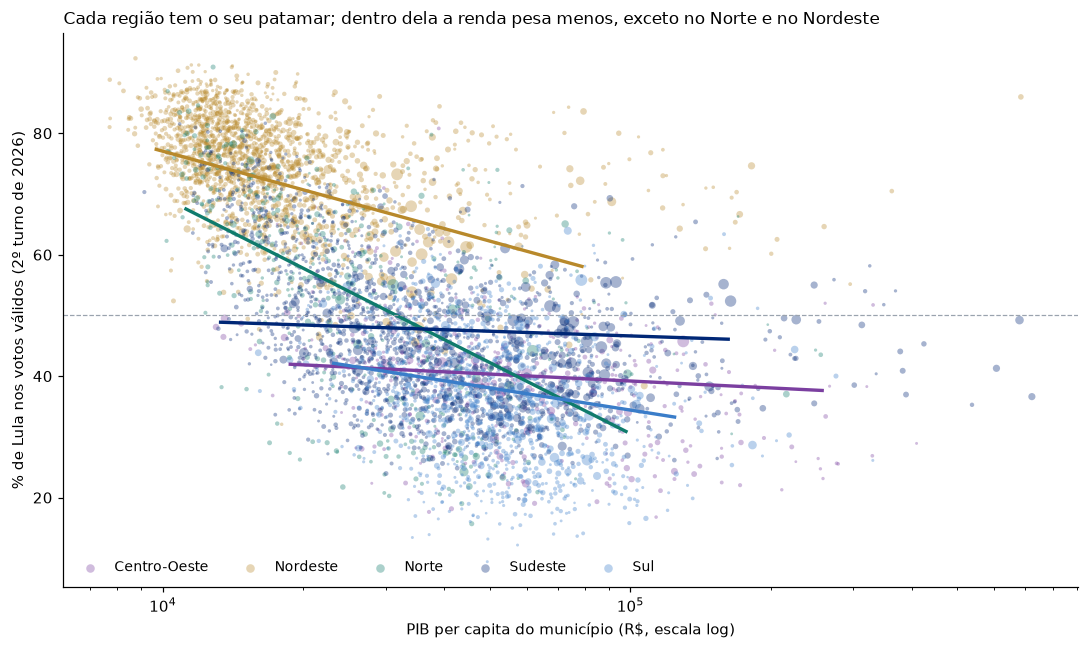

In [8]:
cores = {"Norte": "#0f7b6c", "Nordeste": "#b8892b", "Sudeste": "#002776", "Sul": "#3a7dc9", "Centro-Oeste": "#7b3fa0"}
fig, ax = plt.subplots(figsize=(10, 6), dpi=110)
for regiao, g in d.groupby("regiao"):
    ax.scatter(g.pib_per_capita, g.y * 100, s=np.clip(np.sqrt(g.validos) / 12, 2, 60), alpha=0.35,
               color=cores[regiao], label=regiao, linewidths=0)
    m = smf.wls("y ~ lpib", data=g, weights=g.validos).fit()
    xs = np.linspace(g.lpib.quantile(0.02), g.lpib.quantile(0.98), 50)
    ax.plot(2 ** xs, (m.params.Intercept + m.params.lpib * xs) * 100, color=cores[regiao], lw=2.2)
ax.set_xscale("log")
ax.set_xlabel("PIB per capita do município (R$, escala log)")
ax.set_ylabel("% de Lula nos votos válidos (2º turno de 2026)")
ax.set_title("Cada região tem o seu patamar; dentro dela a renda pesa menos, exceto no Norte e no Nordeste", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncols=5, loc="lower left", fontsize=9)
ax.axhline(50, color="#9aa3ae", lw=0.8, ls="--")
fig.tight_layout()
fig.savefig(FIGURAS / "perfil_renda_regiao.png", bbox_inches="tight")
plt.show()

## Conclusões

- **A relação é forte quando vista sozinha** (Spearman de cerca de −0,74 entre municípios): onde o PIB
  per capita é maior, Lula teve menos votos.
- **Ela encolhe muito com controles.** Dobrar o PIB per capita acompanha cerca de 9 pontos a menos para
  Lula sem controles, cerca de 3 com alfabetização e menos de 2 com alfabetização e região. A região
  explica a maior parte da variação (R² de 0,33 para 0,65).
- **Com controles, o efeito da renda não é estatisticamente distinguível de zero** quando se admite que
  municípios do mesmo estado não são independentes (erros agrupados por UF: intervalo de cerca de −4,0
  a +0,6 ponto). Com erros que ignoram essa dependência (HC1), o intervalo ficaria todo abaixo de zero,
  o que seria uma conclusão otimista demais.
- **O resultado se repete em 2022** com o mesmo tamanho e a mesma incerteza, o que sugere um padrão
  estável, e não um efeito de uma eleição.
- **Limites.** Com 27 UFs, os erros agrupados são aproximados; os dados são agregados por município (falácia ecológica: não dizem como votam pessoas
  ricas ou pobres); o modelo é linear e não inclui outras variáveis relevantes (religião, idade,
  urbanização, programas sociais). Nada aqui é causal.